In [2]:
print("ANN Assignment 4 is starting")

ANN Assignment 4 is starting


***Install and import libraries***

In [3]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, classification_report, roc_auc_score,
    roc_curve, mean_squared_error, r2_score,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


***Upload diabetes.csv file***

In [4]:
from google.colab import files
uploaded = files.upload()

Saving diabetes.csv to diabetes.csv


In [5]:
import io

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset loaded:", filename)
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded: diabetes.csv
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
# Check dataset information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nOutcome distribution:")
print(df["Outcome"].value_counts())

Dataset shape: (768, 9)

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'Pedigree', 'Age', 'Outcome']

Missing values:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64

Duplicate rows: 0

Outcome distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


***Check outliers and correlation***

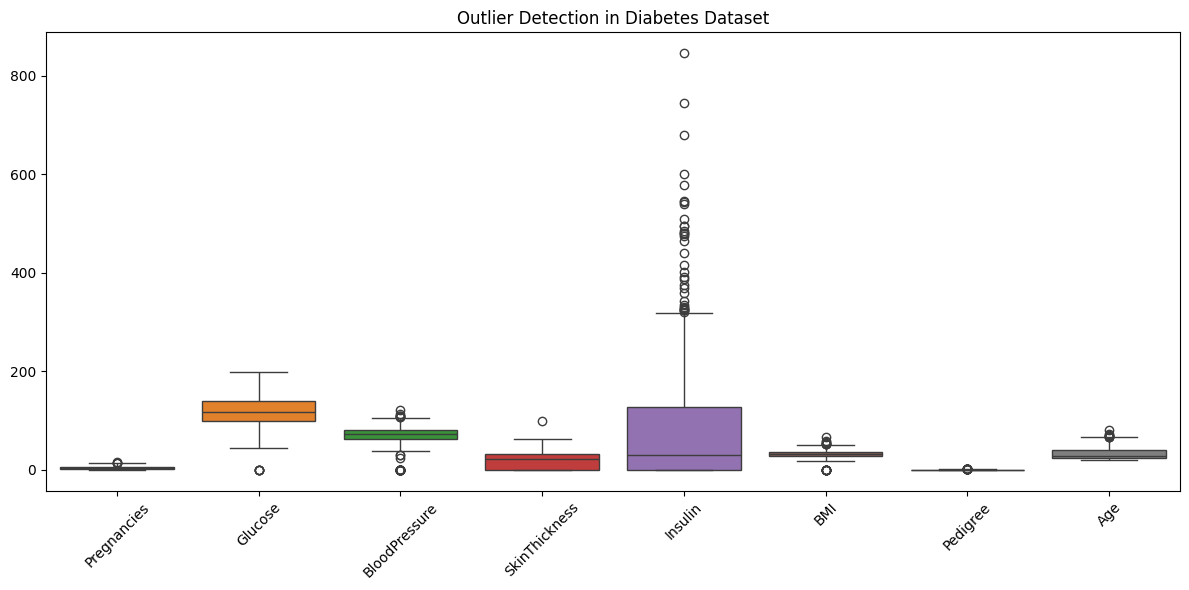

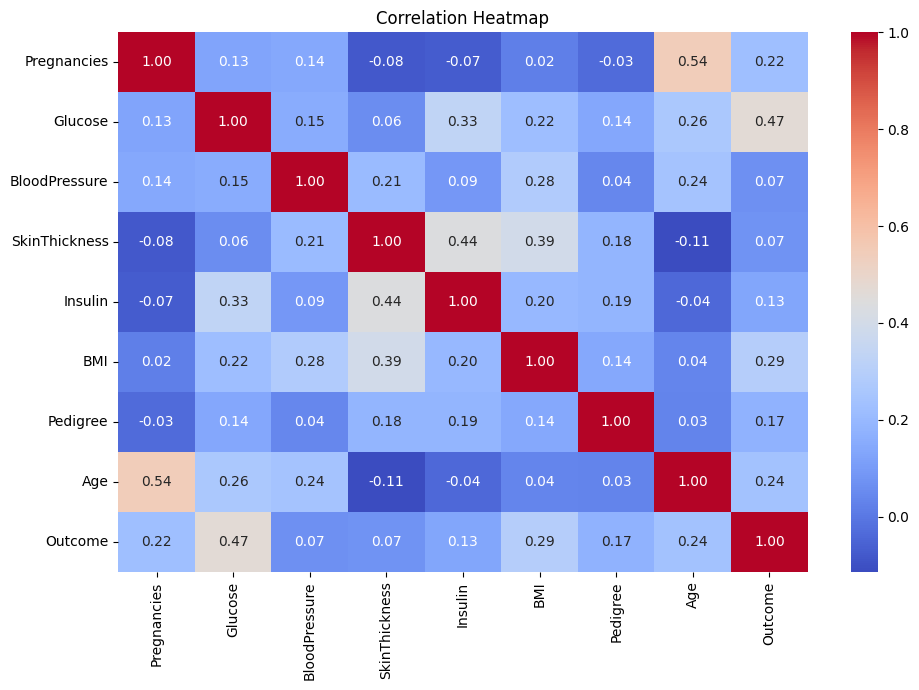

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Boxplots for outlier detection
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.drop(columns=["Outcome"]))
plt.title("Outlier Detection in Diabetes Dataset")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

***Separate features and target***

In [8]:
# X contains input features
X = df.drop(columns=["Outcome"])

# y contains the target
y = df["Outcome"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (768, 8)
Target shape: (768,)


***Split the data into training and testing sets***

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 614
Testing samples: 154


***Train the KNN model***

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=3))
])

knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


***Calculate the required results***

Confusion Matrix:
[[85 15]
 [27 27]]

Accuracy: 0.7273
Error Rate: 0.2727
Precision: 0.6429
Recall: 0.5

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.85      0.80       100
           1       0.64      0.50      0.56        54

    accuracy                           0.73       154
   macro avg       0.70      0.68      0.68       154
weighted avg       0.72      0.73      0.72       154



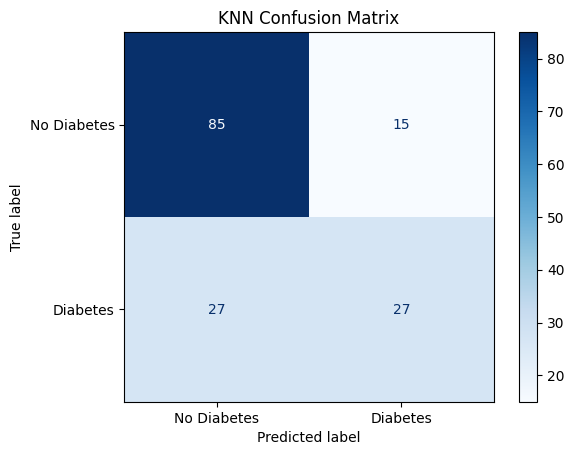

In [11]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Make predictions
y_pred = knn_model.predict(X_test)

# Calculate metrics
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print("Confusion Matrix:")
print(cm)

print("\nAccuracy:", round(accuracy, 4))
print("Error Rate:", round(error_rate, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
).plot(cmap="Blues")

plt.title("KNN Confusion Matrix")
plt.show()

***Improve KNN by choosing a better value of K***

In [12]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15]
}

grid = GridSearchCV(
    knn_model,
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print("Best K:", grid.best_params_["knn__n_neighbors"])
print("Best cross-validation accuracy:", round(grid.best_score_, 4))

# Evaluate the improved model on the test set
best_knn = grid.best_estimator_
best_pred = best_knn.predict(X_test)

print("\nImproved KNN Accuracy:", round(accuracy_score(y_test, best_pred), 4))
print("Improved Confusion Matrix:")
print(confusion_matrix(y_test, best_pred))

Best K: 3
Best cross-validation accuracy: 0.7491

Improved KNN Accuracy: 0.7273
Improved Confusion Matrix:
[[85 15]
 [27 27]]


In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

cm = confusion_matrix(y_test, best_pred, labels=[0, 1])

accuracy = accuracy_score(y_test, best_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, best_pred, zero_division=0)
recall = recall_score(y_test, best_pred, zero_division=0)

print("Confusion Matrix:\n", cm)
print("Accuracy:", round(accuracy, 4))
print("Error Rate:", round(error_rate, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))

print("\nClassification Report:")
print(classification_report(y_test, best_pred))

Confusion Matrix:
 [[85 15]
 [27 27]]
Accuracy: 0.7273
Error Rate: 0.2727
Precision: 0.6429
Recall: 0.5

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.85      0.80       100
           1       0.64      0.50      0.56        54

    accuracy                           0.73       154
   macro avg       0.70      0.68      0.68       154
weighted avg       0.72      0.73      0.72       154



***Compare KNN with Random Forest***

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, roc_auc_score
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("RANDOM FOREST RESULTS")
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_pred))
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))

RANDOM FOREST RESULTS
Confusion Matrix:
 [[88 12]
 [28 26]]
Accuracy: 0.7403
Precision: 0.6842
Recall: 0.4815
ROC-AUC: 0.8075
